<center><h1>Jha_Ria_HW2 - MLDS Assignment</h1></center>
<br>
<br>


Name: Ria Jha
<br>
Github Username: riajha-usc
<br>
USC ID: 8116906970


## 1. Combined Cycle Power Plant Data Set


### (a) Download Data


Package imports


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_squared_error

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid")

Get the Cycle Power Plant Data Set


In [2]:
data_path = Path("data") / "CCPP" / "Folds5x2_pp.xlsx"
ccpp_data_frame = pd.read_excel(data_path, sheet_name="Sheet1")
featureX = ["AT", "V", "AP", "RH"]
targetY = "PE"
ccpp_data_frame.head()

,AT,V,AP,RH,PE
0,14.9600,41.7600,"1,024.0700",73.1700,463.2600
1,25.1800,62.9600,"1,020.0400",59.0800,444.3700
2,5.1100,39.4000,"1,012.1600",92.1400,488.5600
3,20.8600,57.3200,"1,010.2400",76.6400,446.4800
4,10.8200,37.5000,"1,009.2300",96.6200,473.9000


The data was downloaded and is stored in `data/CCPP/Folds5x2_pp.xlsx` inside this repo.


### (b) Exploring the data


#### i. rows and columns


In [3]:
glyphRows, glyphCols = ccpp_data_frame.shape
print(f"Rows: {glyphRows}")
print(f"Columns: {glyphCols}")
print(ccpp_data_frame.dtypes)
print("Missing values per column:")
print(ccpp_data_frame.isna().sum())

Rows: 9568
Columns: 5
AT    float64
V     float64
AP    float64
RH    float64
PE    float64
dtype: object
Missing values per column:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64


**Answer:** The data set has 9568 rows and 5 columns, with no missing values. Each row is one hour of operation of the plant at full load between 2006 and 2011. The values are hourly averages. The columns are the four ambient predictors and the response:

- AT: ambient temperature (degrees C)
- V: exhaust vacuum (cm Hg)
- AP: ambient pressure (millibar)
- RH: relative humidity (%)
- PE: net hourly electrical energy output (MW). This is the response we want to predict.


#### ii. pairwise scatterplots of all the varianbles


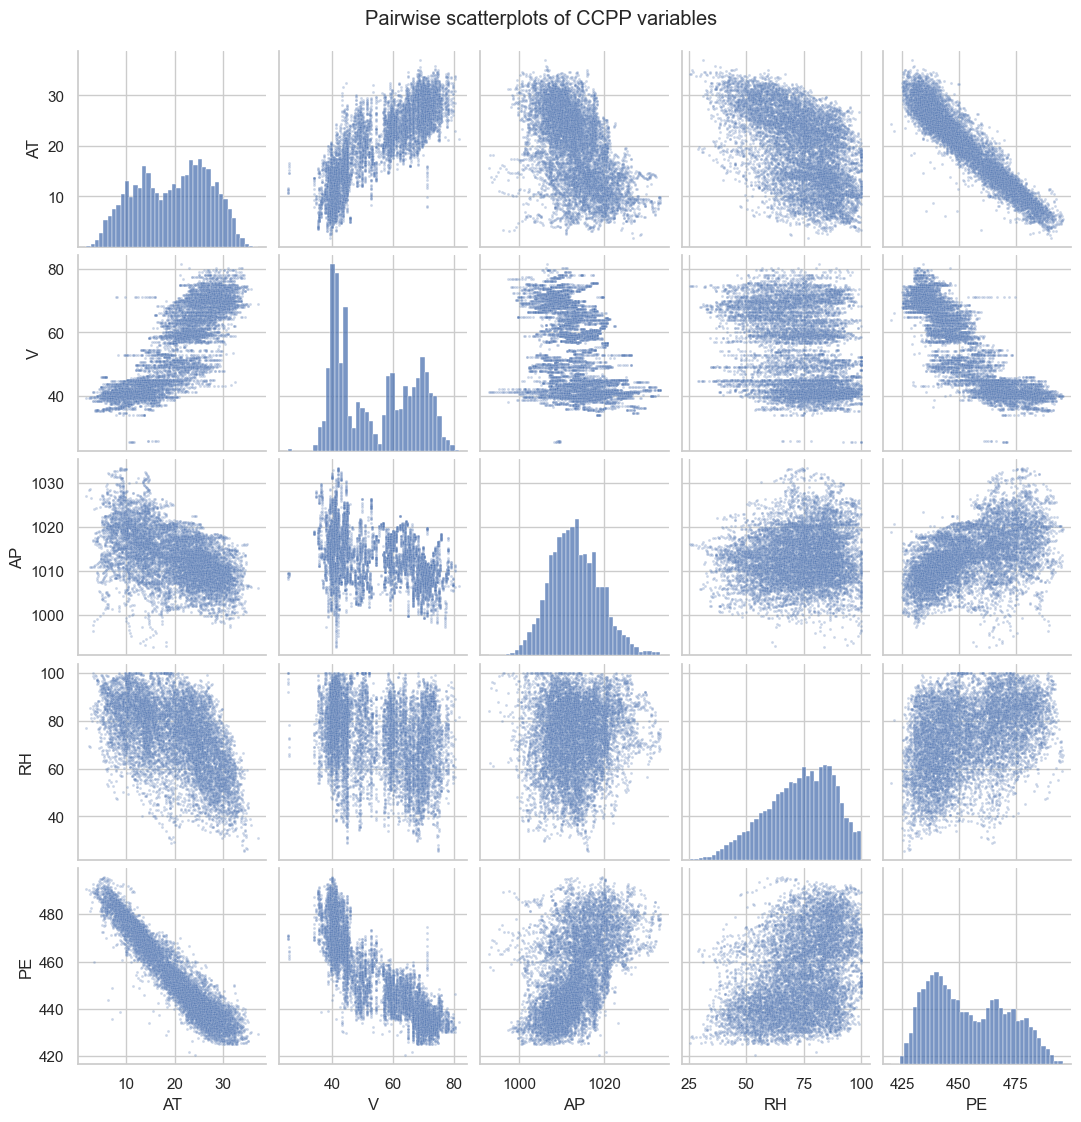

,AT,V,AP,RH,PE
AT,1.0000,0.8440,-0.5080,-0.5430,-0.9480
V,0.8440,1.0000,-0.4140,-0.3120,-0.8700
AP,-0.5080,-0.4140,1.0000,0.1000,0.5180
RH,-0.5430,-0.3120,0.1000,1.0000,0.3900
PE,-0.9480,-0.8700,0.5180,0.3900,1.0000


In [4]:
mosaicGrid = sns.pairplot(ccpp_data_frame, plot_kws={"s": 4, "alpha": 0.3}, diag_kws={"bins": 40}, height=2.2)
mosaicGrid.fig.suptitle("Pairwise scatterplots of CCPP variables", y=1.02)
plt.show()

ccpp_data_frame.corr().round(3)

**Findings:**

- AT vs PE has a very strong, almost linear negative relationship (r = -0.948). Hotter air means less power output. This is the strongest single predictor.
- V vs PE is also strongly negative (r = -0.870), but the cloud is wider and has visible vertical bands, since V takes clustered values.
- AP vs PE is weakly positive (r = 0.518) with a lot of spread.
- RH vs PE is weakly positive (r = 0.390) with the most scatter of the four.
- Among the predictors, AT and V are strongly correlated (r = 0.844), so there is collinearity between them. AT is also moderately negatively correlated with AP (-0.508) and RH (-0.543). AP and RH are nearly uncorrelated (0.100).
- The histograms show that AT, V and PE are bimodal, which hints at two operating regimes (for example cold and warm seasons). AP looks close to normal, and RH is left skewed and capped near 100%.


#### iii. mean, the median, range, first and third quartiles, and interquartile ranges


In [5]:
def tallyQuirks(frame):
    lowQuart = frame.quantile(0.25)
    highQuart = frame.quantile(0.75)
    return pd.DataFrame({
        "Mean": frame.mean(),
        "Median": frame.median(),
        "Min": frame.min(),
        "Max": frame.max(),
        "Range": frame.max() - frame.min(),
        "Q1": lowQuart,
        "Q3": highQuart,
        "IQR": highQuart - lowQuart,
    })

tallyQuirks(ccpp_data_frame)

,Mean,Median,Min,Max,Range,Q1,Q3,IQR
AT,19.6512,20.3450,1.8100,37.1100,35.3000,13.5100,25.7200,12.2100
V,54.3058,52.0800,25.3600,81.5600,56.2000,41.7400,66.5400,24.8000
AP,"1,013.2591","1,012.9400",992.8900,"1,033.3000",40.4100,"1,009.1000","1,017.2600",8.1600
RH,73.3090,74.9750,25.5600,100.1600,74.6000,63.3275,84.8300,21.5025
PE,454.3650,451.5500,420.2600,495.7600,75.5000,439.7500,468.4300,28.6800


**Summary:** The table above lists the mean, median, min, max, range, Q1, Q3 and IQR for every variable. Some notes:

- AP has a large mean (about 1013 mbar) but a small range (40.4) and IQR (8.2), so it varies very little relative to its size.
- The mean and median are close for every variable, so none of them is heavily skewed. RH has mean < median (73.3 vs 75.0), which matches its left skew.
- PE ranges from 420.3 to 495.8 MW, with an IQR of 28.7 MW.


### (c) Simple Linear Regression


,Intercept,Slope,Std Err,t,p-value,R^2,F
Predictor,,,,,,,
AT,497.0341,-2.1713,0.0074,-291.7152,0.0000,0.8989,"85,097.7552"
V,517.8015,-1.1681,0.0068,-172.4015,0.0000,0.7565,"29,722.2909"
AP,"-1,055.2610",1.4899,0.0251,59.2962,0.0000,0.2688,"3,516.0432"
RH,420.9618,0.4557,0.0110,41.3987,0.0000,0.1519,"1,713.8548"


==================== PE ~ AT ====================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    497.0341      0.156   3177.280      0.000     496.727     497.341
AT            -2.1713      0.007   -291.715      0.000      -2.186      -2.157

==================== PE ~ V ====================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    517.8015      0.378   1370.218      0.000     517.061     518.542
V             -1.1681      0.007   -172.402      0.000      -1.181      -1.155

==================== PE ~ AP ====================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -1055.2610     25.459    -41.449      0.000   -1

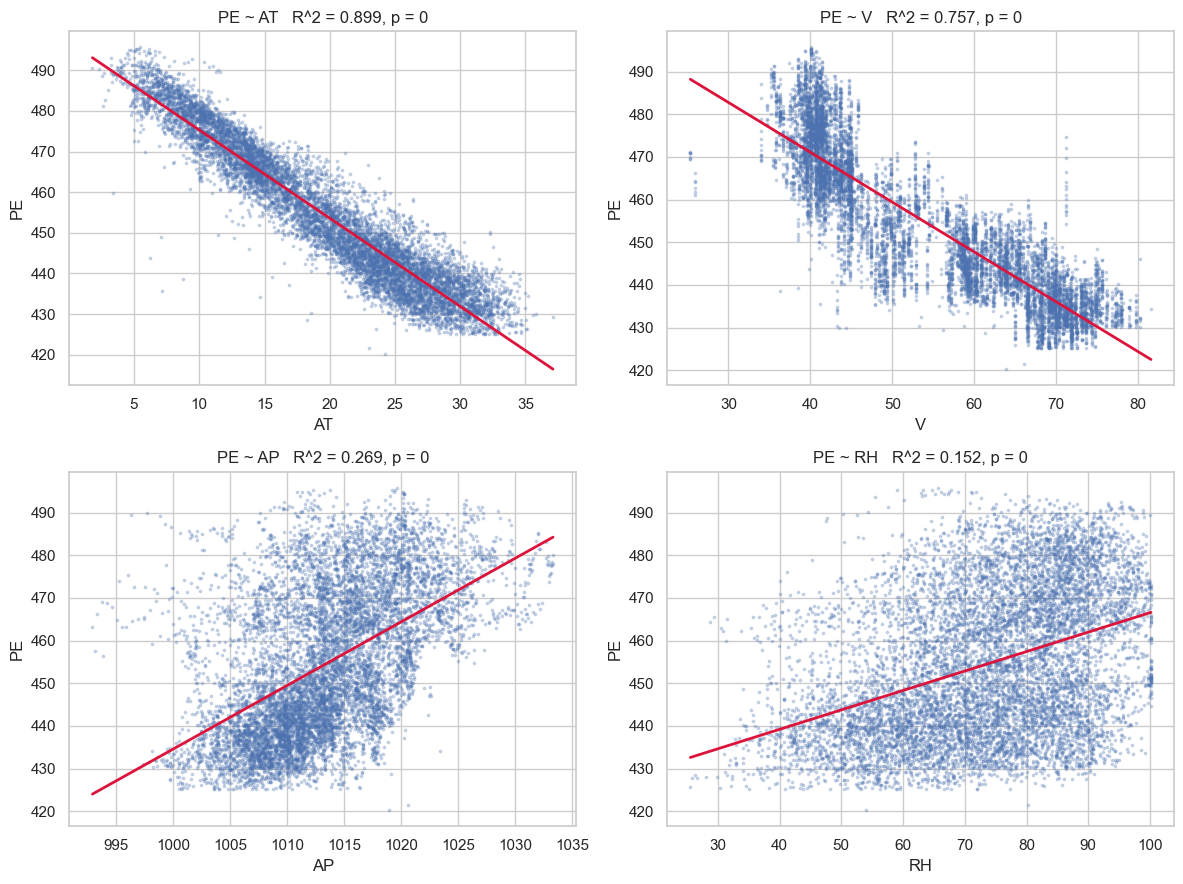

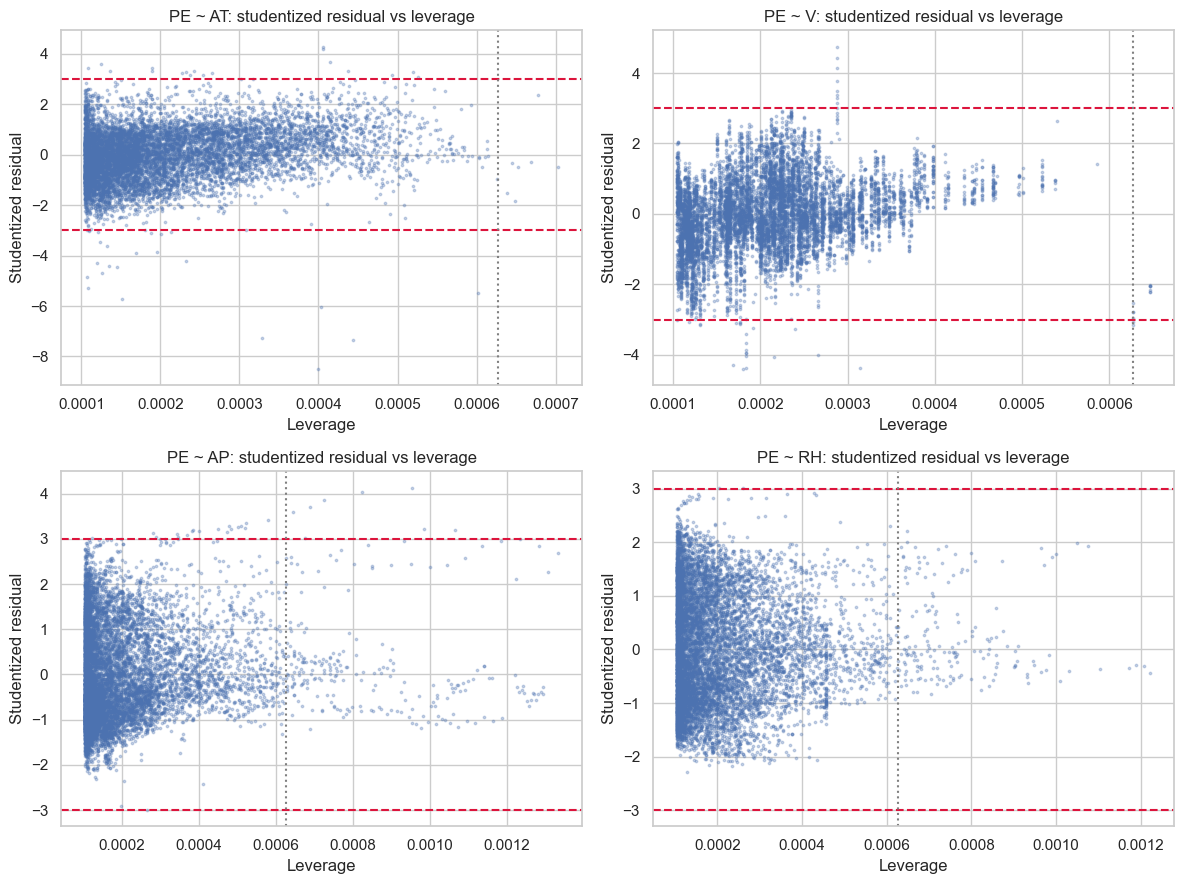

,|stud resid| > 3,leverage > 3p/n,Cook's D > 4/n,max Cook's D
Predictor,,,,
AT,42,7,416,0.0143
V,33,13,423,0.0032
AP,30,239,300,0.0082
RH,2,173,249,0.0021


In [6]:
loneFits = {}
for omen in featureX:
    loneFits[omen] = smf.ols(f"{targetY} ~ {omen}", data=ccpp_data_frame).fit()

def distilLoneFit(fitObj, omen):
    return {
        "Predictor": omen,
        "Intercept": fitObj.params["Intercept"],
        "Slope": fitObj.params[omen],
        "Std Err": fitObj.bse[omen],
        "t": fitObj.tvalues[omen],
        "p-value": fitObj.pvalues[omen],
        "R^2": fitObj.rsquared,
        "F": fitObj.fvalue,
    }

loneDigest = pd.DataFrame([distilLoneFit(loneFits[o], o) for o in featureX]).set_index("Predictor")
display(loneDigest)

for omen in featureX:
    print(f"==================== {targetY} ~ {omen} ====================")
    print(loneFits[omen].summary().tables[1])
    print()

fig, axGrid = plt.subplots(2, 2, figsize=(12, 9))
for axOne, omen in zip(axGrid.ravel(), featureX):
    fitObj = loneFits[omen]
    axOne.scatter(ccpp_data_frame[omen], ccpp_data_frame[targetY], s=3, alpha=0.25)
    spanX = np.linspace(ccpp_data_frame[omen].min(), ccpp_data_frame[omen].max(), 200)
    axOne.plot(spanX, fitObj.params["Intercept"] + fitObj.params[omen] * spanX, color="crimson", lw=2)
    axOne.set_title(f"PE ~ {omen}   R^2 = {fitObj.rsquared:.3f}, p = {fitObj.pvalues[omen]:.2g}")
    axOne.set_xlabel(omen)
    axOne.set_ylabel(targetY)
plt.tight_layout()
plt.show()

def sniffOddballs(fitObj):
    probe = fitObj.get_influence()
    studResid = probe.resid_studentized_external
    leverHat = probe.hat_matrix_diag
    cookDist = probe.cooks_distance[0]
    return studResid, leverHat, cookDist

nObs = len(ccpp_data_frame)
cookFence = 4 / nObs
oddballRows = []
fig, axGrid = plt.subplots(2, 2, figsize=(12, 9))
for axOne, omen in zip(axGrid.ravel(), featureX):
    studResid, leverHat, cookDist = sniffOddballs(loneFits[omen])
    axOne.scatter(leverHat, studResid, s=3, alpha=0.3)
    axOne.axhline(3, color="crimson", ls="--")
    axOne.axhline(-3, color="crimson", ls="--")
    axOne.axvline(3 * 2 / nObs, color="gray", ls=":")
    axOne.set_title(f"PE ~ {omen}: studentized residual vs leverage")
    axOne.set_xlabel("Leverage")
    axOne.set_ylabel("Studentized residual")
    oddballRows.append({
        "Predictor": omen,
        "|stud resid| > 3": int((np.abs(studResid) > 3).sum()),
        "leverage > 3p/n": int((leverHat > 3 * 2 / nObs).sum()),
        "Cook's D > 4/n": int((cookDist > cookFence).sum()),
        "max Cook's D": cookDist.max(),
    })
plt.tight_layout()
plt.show()
pd.DataFrame(oddballRows).set_index("Predictor")

**Results:**

| Model   | Slope  | p-value  | R^2   |
| ------- | ------ | -------- | ----- |
| PE ~ AT | -2.171 | < 1e-300 | 0.899 |
| PE ~ V  | -1.168 | < 1e-300 | 0.757 |
| PE ~ AP | 1.490  | ~0       | 0.269 |
| PE ~ RH | 0.456  | ~0       | 0.152 |

- In all four models there is a statistically significant association between the predictor and PE. Every slope has |t| > 41 and a p-value that is effectively 0, far below 0.05, so we reject $H_0: \beta_1 = 0$ in each case.
- Statistical significance is not the same as explanatory power, though. AT alone explains about 90% of the variance in PE, and V explains about 76%. AP and RH explain only 27% and 15%. With n = 9568, even weak relationships come out as highly significant.
- The fitted line plots back this up. The AT points hug the line closely, while the AP and RH points form wide clouds around it.

**Outliers:** The studentized residual vs leverage plots show a handful of points with |studentized residual| > 3 (42 for AT, 33 for V, 30 for AP, 2 for RH). However:

- the largest Cook's distance in every model is tiny (at most 0.014, far below the usual cutoff of 1), so no single point changes the fitted line in any meaningful way;
- these points are only about 0.4% of the data, and they look like real plant measurements rather than data entry errors;
- the high leverage points for AP and RH are simply the extreme but valid weather conditions.

So I would not remove any outliers. They are not influential, and dropping them would only make the fit look better than it really is. If something had to be flagged, the few AT points with studentized residuals below -5 are the most unusual, but even those have negligible influence.


### (d) Multiple Regression


In [7]:
fullFit = smf.ols(f"{targetY} ~ " + " + ".join(featureX), data=ccpp_data_frame).fit()
print(fullFit.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 3.114e+04
Date:                Fri, 25 Sep 2026   Prob (F-statistic):               0.00
Time:                        18:11:17   Log-Likelihood:                -28088.
No. Observations:                9568   AIC:                         5.619e+04
Df Residuals:                    9563   BIC:                         5.622e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    454.6093      9.749     46.634      0.0

**Results:** The multiple regression model is

$$\widehat{PE} = 454.61 - 1.978\,AT - 0.234\,V + 0.062\,AP - 0.158\,RH$$

- $R^2$ = 0.929 (adjusted 0.929), and the F statistic is 31,140 with p ~ 0, so the model as a whole is highly significant.
- All four p-values are below 0.001 (t = -129.3, -32.1, 6.6, -37.9), so **we can reject $H_0: \beta_j = 0$ for every predictor: AT, V, AP and RH.**
- AT still dominates. With the other predictors held fixed, a 1 degree C increase in temperature lowers output by about 1.98 MW.
- Using all predictors raises $R^2$ from 0.899 (AT alone) to 0.929.
- The large condition number (2.1e5) partly comes from AP being on a scale of about 1000, and partly from the collinearity between AT and V.


### (e) 1c Compare to 1d


,Simple (1c),Multiple (1d)
AT,-2.1713,-1.9775
V,-1.1681,-0.2339
AP,1.4899,0.0621
RH,0.4557,-0.1581


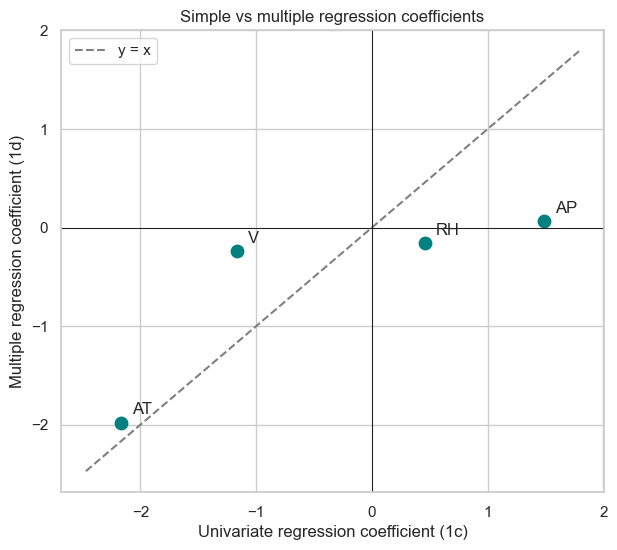

In [8]:
coefDuel = pd.DataFrame({
    "Simple (1c)": [loneFits[o].params[o] for o in featureX],
    "Multiple (1d)": [fullFit.params[o] for o in featureX],
}, index=featureX)
display(coefDuel)

fig, axOne = plt.subplots(figsize=(7, 6))
axOne.scatter(coefDuel["Simple (1c)"], coefDuel["Multiple (1d)"], s=80, color="teal")
for omen, rowVals in coefDuel.iterrows():
    axOne.annotate(omen, (rowVals["Simple (1c)"], rowVals["Multiple (1d)"]),
                   textcoords="offset points", xytext=(8, 6), fontsize=12)
edgeLo = min(coefDuel.min()) - 0.3
edgeHi = max(coefDuel.max()) + 0.3
axOne.plot([edgeLo, edgeHi], [edgeLo, edgeHi], ls="--", color="gray", label="y = x")
axOne.axhline(0, color="black", lw=0.6)
axOne.axvline(0, color="black", lw=0.6)
axOne.set_xlabel("Univariate regression coefficient (1c)")
axOne.set_ylabel("Multiple regression coefficient (1d)")
axOne.set_title("Simple vs multiple regression coefficients")
axOne.legend()
plt.show()

**Comparison:**

- **AT** barely changes (-2.17 to -1.98). It sits close to the y = x line because it is the main driver of PE on its own.
- **V** shrinks a lot (-1.17 to -0.23). Most of its simple regression effect came from its high correlation with AT (r = 0.84). Once AT is in the model, V adds much less on its own.
- **AP** drops from 1.49 to 0.06. The simple regression slope was mostly picking up AP's negative correlation with AT.
- **RH changes sign** (+0.46 to -0.16). In the simple model RH looked helpful only because humid hours tend to be cooler (r(AT, RH) = -0.54). After controlling for AT, higher humidity is slightly harmful.

So the simple regressions in 1c mix each predictor's own effect with the effects of the correlated predictors it stands in for. The multiple regression in 1d separates these partial effects, which is why only AT stays close to the diagonal in the plot.


### (f) Nonlinear Association


==================== PE ~ AT + AT^2 + AT^3 ====================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        452.7081      0.074   6085.240      0.000     452.562     452.854
AT            -2.4297      0.015   -167.160      0.000      -2.458      -2.401
AT^2           0.0326      0.001     33.381      0.000       0.031       0.034
AT^3           0.0027      0.000     22.594      0.000       0.002       0.003

==================== PE ~ V + V^2 + V^3 ====================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        451.2137      0.144   3124.596      0.000     450.931     451.497
V             -1.2503      0.015    -85.722      0.000      -1.279      -1.222
V^2            0.0192      0.001     24.714      0.000       0.018       0.021
V^3  

,p(X),p(X^2),p(X^3),R^2 linear,R^2 cubic
Predictor,,,,,
AT,0.0000,0.0000,0.0000,0.8989,0.9119
V,0.0000,0.0000,0.0137,0.7565,0.7750
AP,0.0000,0.0000,0.0000,0.2688,0.2975
RH,0.0000,0.1014,0.0000,0.1519,0.1537


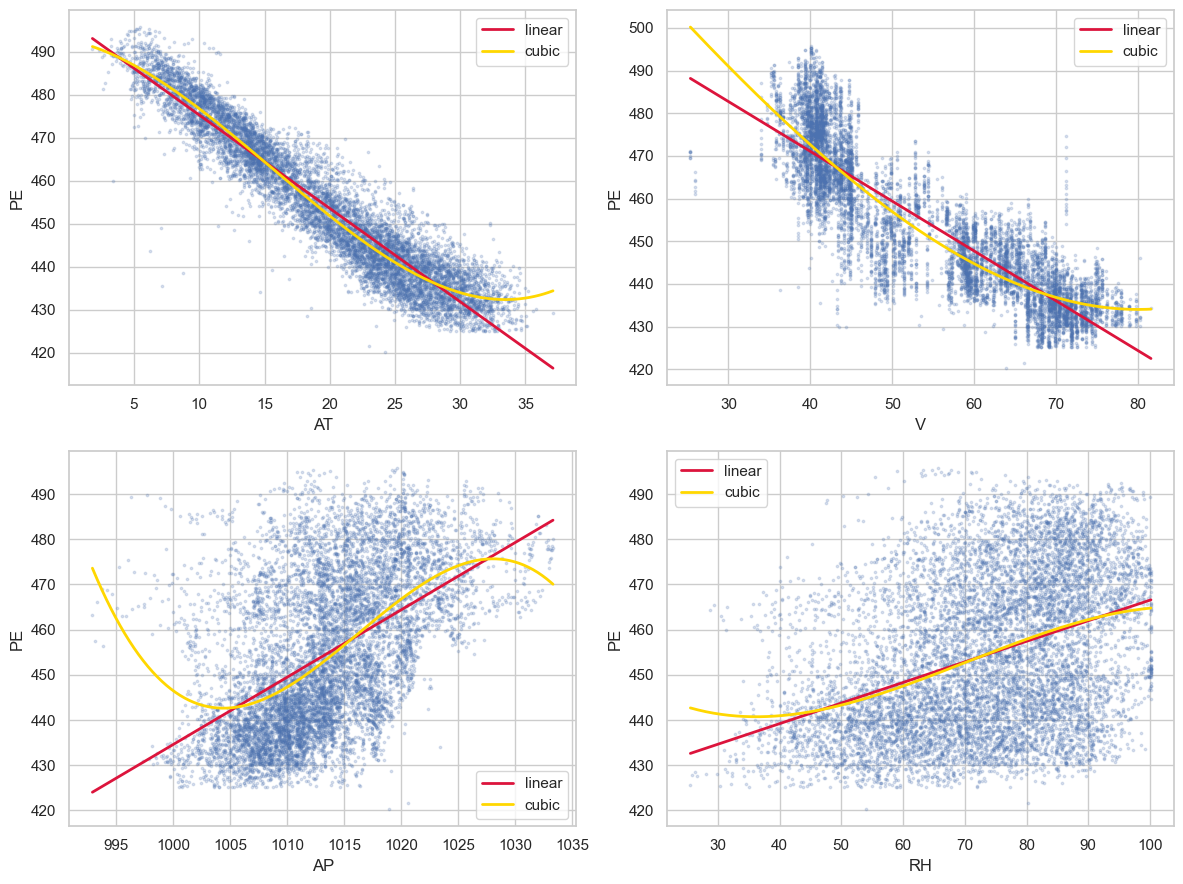

In [9]:
def brewCubicFit(omen):
    cubeMaker = PolynomialFeatures(degree=3, include_bias=False)
    # center X first so X^3 (about 1e9 for AP) does not make the design matrix singular
    cubeMatrix = cubeMaker.fit_transform(ccpp_data_frame[[omen]] - ccpp_data_frame[omen].mean())
    cubeFrame = pd.DataFrame(cubeMatrix, columns=[f"{omen}", f"{omen}^2", f"{omen}^3"])
    return sm.OLS(ccpp_data_frame[targetY], sm.add_constant(cubeFrame)).fit()

cubicFits = {omen: brewCubicFit(omen) for omen in featureX}
cubicRows = []
for omen, fitObj in cubicFits.items():
    print(f"==================== {targetY} ~ {omen} + {omen}^2 + {omen}^3 ====================")
    print(fitObj.summary().tables[1])
    print()
    cubicRows.append({
        "Predictor": omen,
        "p(X)": fitObj.pvalues.iloc[1],
        "p(X^2)": fitObj.pvalues.iloc[2],
        "p(X^3)": fitObj.pvalues.iloc[3],
        "R^2 linear": loneFits[omen].rsquared,
        "R^2 cubic": fitObj.rsquared,
    })
display(pd.DataFrame(cubicRows).set_index("Predictor"))

fig, axGrid = plt.subplots(2, 2, figsize=(12, 9))
for axOne, omen in zip(axGrid.ravel(), featureX):
    spanX = np.linspace(ccpp_data_frame[omen].min(), ccpp_data_frame[omen].max(), 300)
    spanFrame = pd.DataFrame(PolynomialFeatures(degree=3, include_bias=False).fit_transform(spanX.reshape(-1, 1) - ccpp_data_frame[omen].mean()),
                             columns=[f"{omen}", f"{omen}^2", f"{omen}^3"])
    axOne.scatter(ccpp_data_frame[omen], ccpp_data_frame[targetY], s=3, alpha=0.2)
    axOne.plot(spanX, loneFits[omen].params["Intercept"] + loneFits[omen].params[omen] * spanX,
               color="crimson", lw=2, label="linear")
    axOne.plot(spanX, cubicFits[omen].predict(sm.add_constant(spanFrame, has_constant="add")),
               color="gold", lw=2, label="cubic")
    axOne.set_xlabel(omen)
    axOne.set_ylabel(targetY)
    axOne.legend()
plt.tight_layout()
plt.show()

**Answer:** Yes, there is evidence of nonlinear association. Each predictor was centered before building $X, X^2, X^3$. Centering does not change the fitted curve or the test on the highest order term, and it avoids a singular design matrix, since $AP^3$ is around $10^9$.

- **AT:** both $AT^2$ and $AT^3$ are highly significant (p ~ 0), and $R^2$ rises from 0.899 to 0.912. This is clear nonlinearity, and the cubic curve bends at both ends of the temperature range.
- **V:** $V^2$ (p ~ 0) and $V^3$ (p = 0.014) are significant, and $R^2$ rises from 0.757 to 0.775.
- **AP:** $AP^2$ and $AP^3$ are both significant (p ~ 0), and $R^2$ rises from 0.269 to 0.298.
- **RH:** $RH^3$ is significant (p < 0.001), but $RH^2$ is not (p = 0.10). The gain in $R^2$ is tiny (0.152 to 0.154), so the nonlinear part for RH is statistically detectable but practically negligible.

Because n is large, small curvature still produces small p-values, so the change in $R^2$ is a better guide to how much the nonlinearity matters. It matters most for AT and V.


### (g) Interactions of Predictors


In [10]:
tangleFit = smf.ols(f"{targetY} ~ (" + " + ".join(featureX) + ")**2", data=ccpp_data_frame).fit()
print(tangleFit.summary())

tangleTerms = [t for t in tangleFit.params.index if ":" in t]
pd.DataFrame({"coef": tangleFit.params[tangleTerms], "p-value": tangleFit.pvalues[tangleTerms],
              "significant at 0.05": tangleFit.pvalues[tangleTerms] < 0.05})

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.936
Method:                 Least Squares   F-statistic:                 1.405e+04
Date:                Fri, 25 Sep 2026   Prob (F-statistic):               0.00
Time:                        18:11:17   Log-Likelihood:                -27548.
No. Observations:                9568   AIC:                         5.512e+04
Df Residuals:                    9557   BIC:                         5.520e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    685.7825     78.640      8.721      0.0

,coef,p-value,significant at 0.05
AT:V,0.0210,0.0000,True
AT:AP,0.0018,0.4521,False
AT:RH,-0.0052,0.0000,True
V:AP,0.0068,0.0000,True
V:RH,0.0008,0.0862,False
AP:RH,-0.0016,0.0336,True


**Answer:** Yes. In the full model with all six pairwise interactions ($R^2$ = 0.936, compared with 0.929 without interactions):

- **Significant at the 0.05 level:** AT:V (p ~ 0), AT:RH (p ~ 0), V:AP (p ~ 0) and AP:RH (p = 0.034).
- **Not significant:** AT:AP (p = 0.45) and V:RH (p = 0.086).

The strongest one is AT:V (t = 23.3), so the effect of temperature on output depends on the exhaust vacuum level. Once the interactions are included, some main effects (AT, AP, RH) have p-values near 0.05. That is expected, because the main effects and their products are highly collinear. The main effects should still stay in the model under the hierarchy principle.


### (h) Improvement


In [11]:
sproutSeed = 552
trainSlab, testSlab = train_test_split(ccpp_data_frame, train_size=0.7, random_state=sproutSeed)
print("Train size:", len(trainSlab), " Test size:", len(testSlab))

def gaugeMse(fitObj, slab):
    return mean_squared_error(slab[targetY], fitObj.predict(slab))

plainFit = smf.ols(f"{targetY} ~ " + " + ".join(featureX), data=trainSlab).fit()
plainTrainMse = gaugeMse(plainFit, trainSlab)
plainTestMse = gaugeMse(plainFit, testSlab)
print(f"Linear (all predictors)  train MSE = {plainTrainMse:.4f}   test MSE = {plainTestMse:.4f}")

def kinTermsOf(term):
    if ":" in term:
        return set(term.split(":"))
    if term.startswith("I("):
        return {term[2:].split(" ")[0].split("**")[0]}
    return set()

def whittleFormula(frame, startTerms, alphaCut=0.05):
    keptTerms = list(startTerms)
    shedLog = []
    while True:
        fitObj = smf.ols(f"{targetY} ~ " + " + ".join(keptTerms), data=frame).fit()
        guardedMains = set().union(*[kinTermsOf(t) for t in keptTerms])
        droppable = fitObj.pvalues.drop("Intercept")
        droppable = droppable[[t for t in droppable.index if t not in guardedMains]]
        if droppable.empty or droppable.max() <= alphaCut:
            return fitObj, keptTerms, shedLog
        worstTerm = droppable.idxmax()
        shedLog.append((worstTerm, droppable.max()))
        keptTerms.remove(worstTerm)

squareTerms = [f"I({o} ** 2)" for o in featureX]
pairTerms = [f"{a}:{b}" for i, a in enumerate(featureX) for b in featureX[i + 1:]]
lushTerms = featureX + pairTerms + squareTerms

lushFit = smf.ols(f"{targetY} ~ " + " + ".join(lushTerms), data=trainSlab).fit()
print(f"Full interaction + quadratic model  train MSE = {gaugeMse(lushFit, trainSlab):.4f}   test MSE = {gaugeMse(lushFit, testSlab):.4f}")

prunedFit, prunedTerms, shedLog = whittleFormula(trainSlab, lushTerms)
print("Removed terms (in order):")
for termName, pVal in shedLog:
    print(f"   {termName:15s} p = {pVal:.4f}")
print("Kept terms:", prunedTerms)
print(prunedFit.summary())

prunedTrainMse = gaugeMse(prunedFit, trainSlab)
prunedTestMse = gaugeMse(prunedFit, testSlab)
mseBoard = pd.DataFrame({
    "Train MSE": [plainTrainMse, gaugeMse(lushFit, trainSlab), prunedTrainMse],
    "Test MSE": [plainTestMse, gaugeMse(lushFit, testSlab), prunedTestMse],
}, index=["Linear, all predictors", "All interactions + quadratics", "Pruned by p-values"])
mseBoard

Train size: 6697  Test size: 2871
Linear (all predictors)  train MSE = 20.3547   test MSE = 21.7414
Full interaction + quadratic model  train MSE = 17.6979   test MSE = 19.0818
Removed terms (in order):
   AT:AP           p = 0.4923
   V:RH            p = 0.3791
   I(V ** 2)       p = 0.0931
Kept terms: ['AT', 'V', 'AP', 'RH', 'AT:V', 'AT:RH', 'V:AP', 'AP:RH', 'I(AT ** 2)', 'I(AP ** 2)', 'I(RH ** 2)']
                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.939
Model:                            OLS   Adj. R-squared:                  0.939
Method:                 Least Squares   F-statistic:                     9401.
Date:                Fri, 25 Sep 2026   Prob (F-statistic):               0.00
Time:                        18:11:18   Log-Likelihood:                -19126.
No. Observations:                6697   AIC:                         3.828e+04
Df Residuals:                    6685   BI

,Train MSE,Test MSE
"Linear, all predictors",20.3547,21.7414
All interactions + quadratics,17.6979,19.0818
Pruned by p-values,17.7087,19.0829


**Answer:** Yes, the model improves a little.

| Model                                    | Train MSE | Test MSE |
| ---------------------------------------- | --------- | -------- |
| Linear, all predictors                   | 20.355    | 21.741   |
| All interactions + quadratics (14 terms) | 17.698    | 19.082   |
| Pruned by p-values (11 terms)            | 17.709    | 19.083   |

- The data was split 70/30 (6697 train, 2871 test) with `random_state=552`.
- Backward elimination at alpha = 0.05 removed **AT:AP** (p = 0.49), **V:RH** (p = 0.38) and **$V^2$** (p = 0.09), in that order. Following the hierarchy principle, a main effect was never allowed to be dropped while an interaction or square containing it was still in the model. All 11 remaining terms are significant.
- The pruned model lowers test MSE from 21.74 to 19.08 (about 12% lower) compared with the plain linear model, and it matches the full 14 term model with fewer terms. The train and test MSEs are close, so there is no sign of overfitting.
- So adding interactions and quadratic terms helps, and the insignificant terms can be removed without losing any accuracy.


### (i) KNN


,best k,train MSE,test MSE
raw,5.0000,10.1173,17.2225
normalized,6.0000,10.0778,16.0017


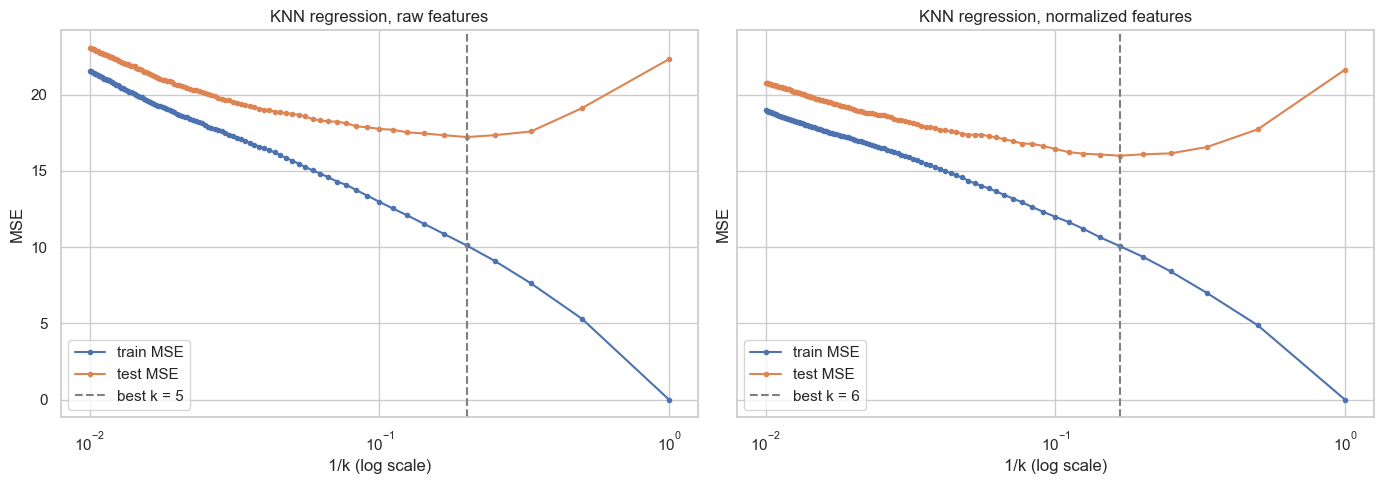

In [12]:
trainOmens, testOmens = trainSlab[featureX].values, testSlab[featureX].values
trainYield, testYield = trainSlab[targetY].values, testSlab[targetY].values

scaleSmith = StandardScaler().fit(trainOmens)
featureFlavors = {
    "raw": (trainOmens, testOmens),
    "normalized": (scaleSmith.transform(trainOmens), scaleSmith.transform(testOmens)),
}

kLadder = np.arange(1, 101)

def sweepNeighbors(trainX, testX):
    trailRows = []
    for kVal in kLadder:
        knnBeast = KNeighborsRegressor(n_neighbors=kVal).fit(trainX, trainYield)
        trailRows.append({
            "k": kVal,
            "train MSE": mean_squared_error(trainYield, knnBeast.predict(trainX)),
            "test MSE": mean_squared_error(testYield, knnBeast.predict(testX)),
        })
    return pd.DataFrame(trailRows).set_index("k")

knnTrails = {flavor: sweepNeighbors(*pair) for flavor, pair in featureFlavors.items()}
bestKnn = pd.DataFrame({
    flavor: {"best k": trail["test MSE"].idxmin(),
             "train MSE": trail.loc[trail["test MSE"].idxmin(), "train MSE"],
             "test MSE": trail["test MSE"].min()}
    for flavor, trail in knnTrails.items()
}).T
display(bestKnn)

fig, axGrid = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for axOne, (flavor, trail) in zip(axGrid, knnTrails.items()):
    invK = 1 / trail.index.values
    axOne.plot(invK, trail["train MSE"], marker="o", ms=3, label="train MSE")
    axOne.plot(invK, trail["test MSE"], marker="o", ms=3, label="test MSE")
    kStar = int(bestKnn.loc[flavor, "best k"])
    axOne.axvline(1 / kStar, color="gray", ls="--", label=f"best k = {kStar}")
    axOne.set_xscale("log")
    axOne.set_xlabel("1/k (log scale)")
    axOne.set_ylabel("MSE")
    axOne.set_title(f"KNN regression, {flavor} features")
    axOne.legend()
plt.tight_layout()
plt.show()

**Answer:** The same 70/30 split from (h) is reused. For the normalized features, the `StandardScaler` is fit on the training set only and then applied to the test set, so no test information leaks into training.

| Features   | Best k | Train MSE | Test MSE |
| ---------- | ------ | --------- | -------- |
| Raw        | 5      | 10.117    | 17.223   |
| Normalized | 6      | 10.078    | 16.002   |

- **Best k = 5 for raw features and k = 6 for normalized features**, chosen by lowest test MSE.
- The plots show the usual bias variance tradeoff against 1/k. Train MSE falls to 0 at k = 1 (1/k = 1), since each point is its own nearest neighbor. Test MSE forms a U shape: large k (small 1/k) underfits, and very small k overfits.
- Normalizing helps (16.00 vs 17.22). Without scaling, V and RH (ranges of 56 and 75) dominate the Euclidean distance, while AP (range 40) and the most important predictor AT (range 35) count for less. Standardizing gives all four predictors equal weight in the distance.


### (j ) Compare KNN and Linear


In [13]:
duelBoard = pd.DataFrame({
    "Train MSE": [plainTrainMse, prunedTrainMse,
                  bestKnn.loc["raw", "train MSE"], bestKnn.loc["normalized", "train MSE"]],
    "Test MSE": [plainTestMse, prunedTestMse,
                 bestKnn.loc["raw", "test MSE"], bestKnn.loc["normalized", "test MSE"]],
}, index=["Linear, all predictors", "Pruned interaction + quadratic",
          f"KNN raw (k={int(bestKnn.loc['raw', 'best k'])})",
          f"KNN normalized (k={int(bestKnn.loc['normalized', 'best k'])})"])
duelBoard

,Train MSE,Test MSE
"Linear, all predictors",20.3547,21.7414
Pruned interaction + quadratic,17.7087,19.0829
KNN raw (k=5),10.1173,17.2225
KNN normalized (k=6),10.0778,16.0017


**Analysis:**

- The best linear regression model is the **pruned interaction + quadratic model**, with test MSE 19.08. (The full 14 term model is practically tied at 19.08.)
- **KNN with normalized features and k = 6 does best overall, with test MSE 16.00**, about 16% lower than the best linear model. Even KNN on raw features (17.22) beats it.
- KNN is nonparametric, so it can pick up local curvature and interactions that a fixed polynomial form cannot. With about 6700 training points in only 4 dimensions, the neighborhoods are dense, so the curse of dimensionality is not an issue here.
- KNN has a much larger gap between train and test error (about 10 vs 16) than the linear models (about 17.7 vs 19.1). This shows that KNN has much higher variance, while the regression models are more stable.
- The linear models are easier to interpret. They give coefficients and p-values (for example, AT lowers output by about 2 MW per degree C), predict almost instantly, and do not have to store the training data. KNN gives no interpretable parameters.

**Conclusion:** If the goal is prediction accuracy, normalized KNN (k = 6) is the better choice for this data. If the goal is understanding how the ambient conditions affect power output, the pruned regression model is more useful, and it gives up only about 3 MW^2 of test MSE.


## 2. ISLR: 2.4.1


### (a) The sample size n is extremely large, and the number of predictors p is small.


**Better.** A flexible method would generally perform better. With a very large n and few predictors, there is enough data to fit a flexible model without overfitting. The variance that flexibility adds stays small, while the lower bias improves the fit.


### (b) The number of predictors p is extremely large, and the number of observations n is small.


**Worse.** A flexible method would generally perform worse. With many predictors and few observations, a flexible method would overfit the noise in the small training set and have high variance. An inflexible method is more stable in this case.


### (c) The relationship between the predictors and response is highly non-linear.


**Better.** A flexible method would generally perform better. An inflexible method (such as linear regression) would have high bias because it cannot capture a highly nonlinear relationship. A flexible method can follow the true shape of f.


### (d) The variance of the error terms, i.e. $σ^2$ = Var(ε), is extremely high.


**Worse.** A flexible method would generally perform worse. When the irreducible error is very high, a flexible method will fit the noise (overfit) and have high variance. An inflexible method averages out more of the noise.


## 3. ISLR: 2.4.7


### (a) Compute the Euclidean distance between each observation and the test point, X1 = X2 = X3 = 0.


In [14]:
pebbleTable = pd.DataFrame({
    "X1": [0, 2, 0, 0, -1, 1],
    "X2": [3, 0, 1, 1, 0, 1],
    "X3": [0, 0, 3, 2, 1, 1],
    "Y": ["Red", "Red", "Red", "Green", "Green", "Red"],
}, index=pd.RangeIndex(1, 7, name="Obs"))
originProbe = np.zeros(3)
pebbleTable["Distance"] = np.sqrt(((pebbleTable[["X1", "X2", "X3"]].values - originProbe) ** 2).sum(axis=1))
pebbleTable

,X1,X2,X3,Y,Distance
Obs,,,,,
1,0,3,0,Red,3.0000
2,2,0,0,Red,2.0000
3,0,1,3,Red,3.1623
4,0,1,2,Green,2.2361
5,-1,0,1,Green,1.4142
6,1,1,1,Red,1.7321


**Answer:** The distance from each observation to the test point (0, 0, 0) is $\sqrt{X_1^2 + X_2^2 + X_3^2}$:

| Obs. | Distance            | Y     |
| ---- | ------------------- | ----- |
| 1    | $\sqrt{9}$ = 3.000  | Red   |
| 2    | $\sqrt{4}$ = 2.000  | Red   |
| 3    | $\sqrt{10}$ = 3.162 | Red   |
| 4    | $\sqrt{5}$ = 2.236  | Green |
| 5    | $\sqrt{2}$ = 1.414  | Green |
| 6    | $\sqrt{3}$ = 1.732  | Red   |


### (b) What is our prediction with K = 1? Why?


In [15]:
def whisperVote(kCount):
    closeFolk = pebbleTable.nsmallest(kCount, "Distance")
    print(closeFolk[["Y", "Distance"]])
    return closeFolk["Y"].mode().iloc[0]

print("Prediction with K = 1:", whisperVote(1))

         Y  Distance
Obs                 
5    Green    1.4142
Prediction with K = 1: Green


**Answer: Green.** With K = 1, we predict the class of the single nearest observation. That is observation 5 (distance 1.414), which is Green.


### (c) What is our prediction with K = 3? Why?


In [16]:
print("Prediction with K = 3:", whisperVote(3))

         Y  Distance
Obs                 
5    Green    1.4142
6      Red    1.7321
2      Red    2.0000
Prediction with K = 3: Red


**Answer: Red.** With K = 3, the three nearest observations are 5 (Green, 1.414), 6 (Red, 1.732) and 2 (Red, 2.000). Two of the three are Red, so the majority vote gives Red.


### (d) If the Bayes decision boundary in this problem is highly non-linear, then would we expect the best value for K to be large or small? Why?


**Answer: Small.** A small K gives a flexible decision boundary that can follow the complex, highly nonlinear shape of the Bayes boundary. A large K averages over many neighbors and gives a smoother, closer to linear boundary, which would have high bias here. So we would expect the best K to be small, but not so small that the model overfits the noise.
